# HW2 — Multi-Agent Systems
## Multi-agent simulation of the Public Goods Game with Cheap Talk

**Model:** Qwen/Qwen3.5-9B, 4-bit NF4 quantised (non-thinking mode), Kaggle GPU
*(Lighter fallback: change `MODEL_ID` in Section 4 to `"Qwen/Qwen3.5-4B"` if needed)*
**Setup:** 4 agents, 10 rounds, 3 scenarios x 3 runs = **660 successful model calls**

---

### What this notebook does

1. Redirects HuggingFace/pip caches to `/tmp` (keeping `/kaggle/working` under its 20 GB limit) and installs `transformers >= 5.2`.
2. Adds the project code to `sys.path` — the code comes from a **Kaggle dataset**, it is not written by the notebook.
3. Prepares the Persian font used by the report.
4. Downloads and loads Qwen3.5-9B in 4-bit (`AutoModelForImageTextToText` + `AutoTokenizer`).
5. Runs a two-call smoke test on the backend and estimates full runtime.
6. Runs all nine games and writes `logs/`.
7. Verifies the 660-call budget and that retries stay out of the game logs.
8. Builds every figure and index required by section 4 of the assignment.
9. Generates `report.html` and converts it to `report.pdf`.

### Dataset layout expected by this notebook

```
hw2-src/
└── pgg/
    ├── __init__.py
    ├── config.py        # all numbers and all model-facing text
    ├── common.py        # records shared by every layer + text helpers
    ├── engine.py        # payoff function and the round loop
    ├── agents.py        # four agent types and the roster factory
    ├── backends.py      # Qwen wrapper + a fake backend
    ├── runner.py        # nine games, writes logs/
    ├── analysis.py      # figures and indices for section 4
    ├── report.py        # report.html -> report.pdf
    ├── submission.py    # packages the final zip
    └── phases/
        ├── chat.py
        └── contribution.py
```

Kaggle settings required: `Settings → Internet → On` and
`Session options → Accelerator → GPU T4 x2` (a single 16 GB T4 also fits in 4-bit).

## 1. Environment setup

In [1]:
import os

# Qwen3.5-9B weights are ~19.3 GB on disk; keep HuggingFace/pip caches in /tmp
# so /kaggle/working (20 GB quota) stays free for logs, figures, and report.pdf.
for k, p in {
    "HF_HOME": "/tmp/hf_cache",
    "HUGGINGFACE_HUB_CACHE": "/tmp/hf_cache/hub",
    "PIP_CACHE_DIR": "/tmp/pip_cache",
    "TMPDIR": "/tmp",
}.items():
    os.makedirs(p, exist_ok=True)
    os.environ[k] = p

!pip install -q -U "transformers>=5.2.0" bitsandbytes accelerate safetensors pillow pydantic matplotlib weasyprint pymupdf 2>&1 | tail -5

# WeasyPrint needs pango/cairo; the Kaggle image ships them, but make the
# dependency explicit so a missing library fails here and not at report time.
import transformers, weasyprint, pymupdf
print(
    "transformers", transformers.__version__,
    "| weasyprint", weasyprint.__version__,
    "| pymupdf", pymupdf.__version__,
)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
transformers 5.24.0 | weasyprint 70.0 | pymupdf 2.1


In [2]:
import os, shutil, sys, torch

print("python :", sys.version.split()[0])
print("torch  :", torch.__version__)
print("cuda   :", torch.cuda.is_available())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        props = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {props.name}  ({props.total_memory / 1e9:.1f} GB)")

for path in ("/tmp", "/kaggle/working"):
    if os.path.exists(path):
        total, used, free = shutil.disk_usage(path)
        print(f"disk {path:15s}: {free / 1e9:.1f} GB free / {total / 1e9:.1f} GB total")

python : 3.13.16
torch  : 2.11.0+cu130
cuda   : True
  GPU 0: Tesla T4  (15.6 GB)
  GPU 1: Tesla T4  (15.6 GB)
disk /tmp           : 2699.3 GB free / 8758.4 GB total
disk /kaggle/working: 20.9 GB free / 21.0 GB total


## 2. Attach the project code

The package lives in a Kaggle dataset. Change `PROJECT_ROOT` only if your
dataset folder has a different name; otherwise the automatic search finds it.

In [3]:
import sys, pathlib

PROJECT_ROOT = pathlib.Path("/kaggle/input/hw2-src")

if not PROJECT_ROOT.exists():
    for candidate in pathlib.Path("/kaggle/input").rglob("pgg/config.py"):
        PROJECT_ROOT = candidate.parent.parent
        break

print("project root:", PROJECT_ROOT)
assert (PROJECT_ROOT / "pgg" / "config.py").exists(), "pgg/ not found in the attached datasets"

sys.path.insert(0, str(PROJECT_ROOT))

import pgg
from pgg import config, common, engine, agents, backends, runner, analysis, report

print("imported from", pgg.__file__)
print("N_PLAYERS, N_ROUNDS, ENDOWMENT, MULTIPLIER =",
      config.N_PLAYERS, config.N_ROUNDS, config.ENDOWMENT, config.MULTIPLIER)
print("calls per scenario:", config.EXPECTED_CALLS, "| total:", config.EXPECTED_TOTAL)

project root: /kaggle/input/datasets/mohammadhossein20/public-goods-game-dataset
imported from /kaggle/input/datasets/mohammadhossein20/public-goods-game-dataset/pgg/__init__.py
N_PLAYERS, N_ROUNDS, ENDOWMENT, MULTIPLIER = 4 10 20 1.6
calls per scenario: {1: 80, 2: 80, 3: 60} | total: 660


## 3. Report font

The report is rendered with Vazirmatn. If the font is not part of a dataset it is
downloaded once from the official release.

In [4]:
import io, pathlib, urllib.request, zipfile

ASSETS = pathlib.Path("/kaggle/working/assets")
ASSETS.mkdir(parents=True, exist_ok=True)
NEEDED = ["Vazirmatn-Regular.ttf", "Vazirmatn-Bold.ttf"]

for base in (pathlib.Path("/kaggle/input"), pathlib.Path(".")):
    if not base.exists():
        continue
    for name in NEEDED:
        if (ASSETS / name).exists():
            continue
        for hit in base.rglob(name):
            (ASSETS / name).write_bytes(hit.read_bytes())
            break

if not all((ASSETS / n).exists() for n in NEEDED):
    print("downloading Vazirmatn...")
    url = ("https://github.com/rastikerdar/vazirmatn/releases/download/"
           "v33.003/vazirmatn-v33.003.zip")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    blob = urllib.request.urlopen(req, timeout=120).read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for entry in z.namelist():
            if pathlib.Path(entry).name in NEEDED:
                (ASSETS / pathlib.Path(entry).name).write_bytes(z.read(entry))

print({p.name: f"{p.stat().st_size // 1024} KB" for p in ASSETS.glob("*.ttf")})

downloading Vazirmatn...
{'Vazirmatn-Regular.ttf': '119 KB', 'Vazirmatn-Bold.ttf': '120 KB'}


## 4. Load the model

`Qwen/Qwen3.5-9B` is loaded in 4-bit (NF4 + double quant, ~6.5–8 GB VRAM), which fits
on Kaggle `T4 x2` (32 GB total) and also fits on a single 16 GB T4.

Key technical details for Qwen3.5:
- Qwen3.5 checkpoints use the conditional-generation class (`Qwen3_5ForConditionalGeneration`),
  so we load with `AutoModelForImageTextToText` (using `AutoModelForCausalLM` can mis-map nested
  `model.language_model.*` weights in `transformers`) together with `AutoTokenizer` for text-only chat.
- `HF_HOME` is pointed at `/tmp/hf_cache` so the ~19.3 GB download does not fill `/kaggle/working`.
- If your session has tight disk/runtime limits, swap `MODEL_ID` below to `"Qwen/Qwen3.5-4B"` (~3.5 GB VRAM).

In [5]:
import gc, torch
from transformers import AutoModelForImageTextToText, AutoTokenizer, BitsAndBytesConfig

MODEL_ID = "Qwen/Qwen3.5-9B"
# Lighter/faster fallback if single-T4 disk or runtime is tight:
# MODEL_ID = "Qwen/Qwen3.5-4B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    quantization_config=bnb,
    dtype=torch.float16,
    attn_implementation="sdpa",
    low_cpu_mem_usage=True,
    device_map="auto",
)
model.eval()
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    for i in range(torch.cuda.device_count()):
        alloc = torch.cuda.memory_allocated(i) / 1e9
        total = torch.cuda.get_device_properties(i).total_memory / 1e9
        print(f"GPU {i} VRAM allocated: {alloc:.2f} / {total:.1f} GB")

print("loaded:", MODEL_ID)
print("device map:", getattr(model, "hf_device_map", "single device"))

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 12.8MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/79.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

GPU 0 VRAM allocated: 3.74 / 15.6 GB
GPU 1 VRAM allocated: 4.16 / 15.6 GB
loaded: Qwen/Qwen3.5-9B
device map: {'model.visual': 0, 'model.language_model.embed_tokens': 0, 'model.language_model.layers.0': 0, 'model.language_model.layers.1': 0, 'model.language_model.layers.2': 0, 'model.language_model.layers.3': 0, 'model.language_model.layers.4': 0, 'model.language_model.layers.5': 0, 'model.language_model.layers.6': 0, 'model.language_model.layers.7': 0, 'model.language_model.layers.8': 0, 'model.language_model.layers.9': 0, 'model.language_model.layers.10': 0, 'model.language_model.layers.11': 0, 'model.language_model.layers.12': 0, 'model.language_model.layers.13': 1, 'model.language_model.layers.14': 1, 'model.language_model.layers.15': 1, 'model.language_model.layers.16': 1, 'model.language_model.layers.17': 1, 'model.language_model.layers.18': 1, 'model.language_model.layers.19': 1, 'model.language_model.layers.20': 1, 'model.language_model.layers.21': 1, 'model.language_model.laye

## 5. Backend smoke test

One call per phase before spending the GPU budget, to confirm the model returns
parseable JSON and that the prompt is assembled correctly.

In [6]:
import time
from pgg.backends import QwenBackend
from pgg.agents import LLMAgent

backend = QwenBackend(model, tokenizer, model_id=MODEL_ID, enable_thinking=False)

probe = LLMAgent(1, "machiavellian", backend,
                 config.rules_prompt(known_horizon=True),
                 temperature=config.TEMPERATURE, seed=101)

t0 = time.time()
obs = {"agent_id": 1, "round": 1, "known_horizon": True, "balance": 0.0, "history": []}
chat_reply = probe.chat(obs)
print("chat phase  :", chat_reply)

transcript = {
    1: (chat_reply or {}).get("chat_message", "I plan to contribute 20."),
    2: "I plan to contribute 20 this round.",
    3: "I plan to contribute 15 this round.",
    4: "I plan to contribute 10 this round.",
}
obs2 = dict(obs, round_chat=transcript,
            my_claim=(chat_reply or {}).get("claimed_contribution", 20))
print("contribution:", probe.contribute(obs2))
dt = time.time() - t0
print(f"retries/errors so far: {len(probe.errors)} | 2-call smoke time: {dt:.1f}s (est. 660 calls: ~{dt * 330 / 60:.0f} min)")

[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.


chat phase  : {'chat_message': 'I pledge to contribute 20 tokens fully to help build our strong collective pot today.', 'claimed_contribution': 20}
contribution: {'reasoning': 'I will contribute 20 tokens to the fund, keeping 0 privately, to establish immediate credibility and encourage others to trust my high pledge, maximizing the collective pot for future exploitation.', 'contribution': 20, 'considers_end': 'group_trust'}
retries/errors so far: 0 | 2-call smoke time: 21.5s (est. 660 calls: ~118 min)


## 6. Run all nine games

| Scenario | Roster | Horizon | Calls per run |
|---|---|---|---|
| 1 | 4 heterogeneous LLM agents | known (T=10) | 80 |
| 2 | 4 heterogeneous LLM agents | unknown | 80 |
| 3 | 3 LLM agents + 1 rule-based defector | known (T=10) | 60 |

The rule-based agent consumes no model calls. Expected runtime for Qwen3.5-9B (non-thinking): ~50–90 minutes (check the smoke-test estimate above).

In [7]:
from pathlib import Path
import time

from pgg.runner import run_all

WORK = Path("/kaggle/working")
started = time.time()
summary = run_all(backend, WORK)
print(f"finished in {(time.time() - started) / 60:.1f} minutes")
summary

finished in 97.9 minutes


{'total_calls': 660,
 'expected_total': 660,
 'by_scenario': {1: 240, 2: 240, 3: 180},
 'runs': 9,
 'structural_errors': 15,
 'temperature': 0.8}

## 7. Verify the 660-call budget

`json.loads` turns object keys into strings, hence `"1"` rather than `1`.

In [8]:
import json, pathlib

idx = json.loads((WORK / "logs/index.json").read_text())
print(json.dumps(idx, indent=2))

assert idx["total_calls"] == 660, f"budget broken: {idx['total_calls']}"
assert idx["by_scenario"] == {"1": 240, "2": 240, "3": 180}, idx["by_scenario"]

files = sorted(WORK.glob("logs/scenario*/run*.json"))
print(f"\n{len(files)} game logs written")

# section 3.3: retried calls must not appear in the game log
game_log = (WORK / "logs/scenario1/run1.json").read_text()
assert "attempts" not in game_log and "raw_response" not in game_log
print("OK: game logs are clean; retries are isolated in logs/diagnostics/")

{
  "total_calls": 660,
  "expected_total": 660,
  "by_scenario": {
    "1": 240,
    "2": 240,
    "3": 180
  },
  "runs": 9,
  "structural_errors": 15,
  "temperature": 0.8
}

9 game logs written
OK: game logs are clean; retries are isolated in logs/diagnostics/


## 8. Analysis (assignment section 4)

Every number is averaged over the three independent runs of each scenario.

In [9]:
import os
from pgg.analysis import build_all, load_logs
from pgg.config import ENDOWMENT

os.chdir(WORK)
logs = load_logs(Path("."))
assert len(logs) == 9, len(logs)

results = build_all(logs, Path("."))
for name, path in results["figures"].items():
    print(f"  {name} -> {path}")


  contribution_curves -> figures/01_contribution_curves.png
  scenario_comparison -> figures/02_scenario_comparison.png
  agent_trajectories_s1 -> figures/03_agents_scenario1.png
  agent_trajectories_s2 -> figures/04_agents_scenario2.png
  agent_trajectories_s3 -> figures/05_agents_scenario3.png
  hypocrisy_scenario1 -> figures/06_hypocrisy_scenario1.png
  hypocrisy_scenario2 -> figures/07_hypocrisy_scenario2.png
  hypocrisy_scenario3 -> figures/08_hypocrisy_scenario3.png
  hypocrisy_by_kind -> figures/09_hypocrisy_by_kind.png
  claimed_vs_actual_s1 -> figures/10_claimed_vs_actual_s1.png
  claimed_vs_actual_s2 -> figures/11_claimed_vs_actual_s2.png
  claimed_vs_actual_s3 -> figures/12_claimed_vs_actual_s3.png
  delta_bars -> figures/13_delta_bars.png
  reasoning_themes -> figures/14_reasoning_themes.png
  defector_response -> figures/15_defector_response.png
  defector_detection -> figures/16_defector_detection.png


### 4.1 Endgame effect — group contribution per round

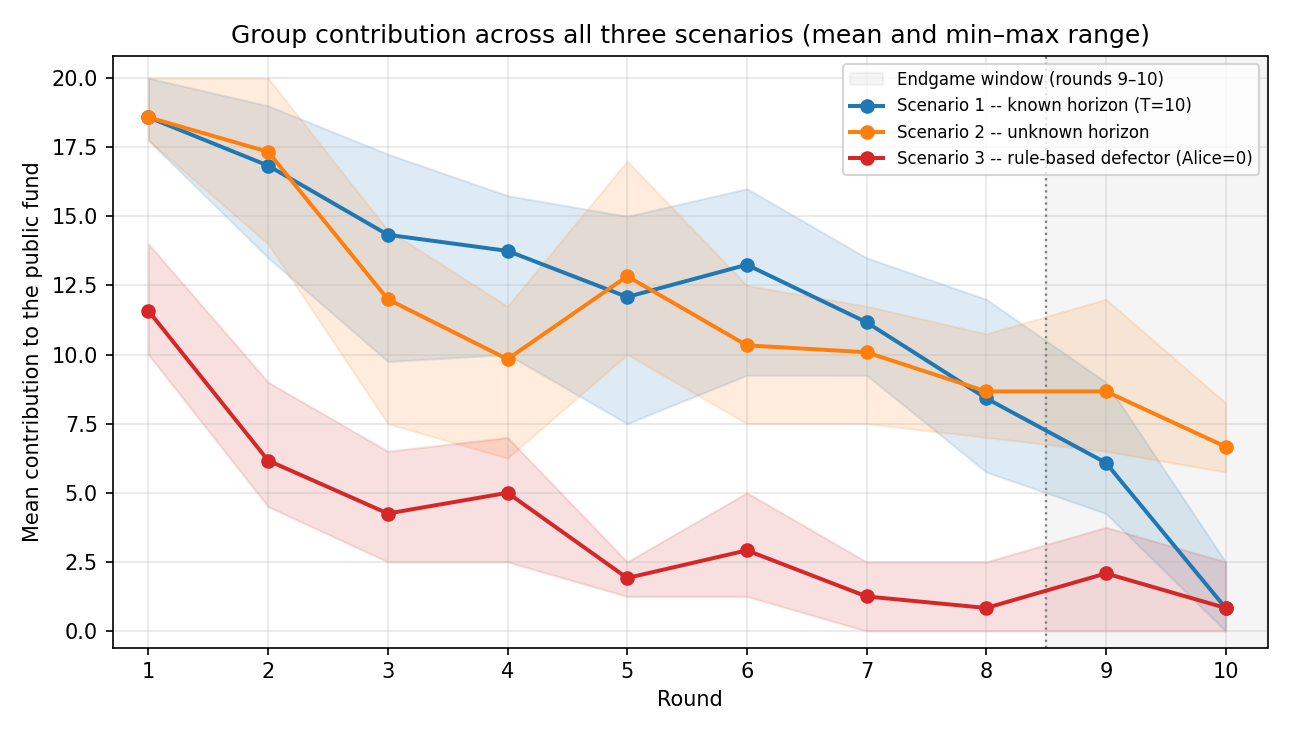

In [10]:
from IPython.display import Image, display
display(Image(filename=results["figures"]["scenario_comparison"]))


**Endgame drop** — delta_i = mean(rounds 9-10) - mean(rounds 5-8):

In [11]:
import pandas as pd

rows = []
for scen_key, per_agent in results["delta_i"].items():
    scenario = int(scen_key[-1])
    ref = next(l for (s, _), l in logs.items() if s == scenario)
    for agent_id, delta in per_agent.items():
        rows.append({
            "scenario": scenario,
            "player": config.agent_name(int(agent_id)),
            "persona": ref.agents[int(agent_id)]["persona"].split(" (")[0],
            "delta_i": round(delta, 2),
        })
pd.DataFrame(rows).pivot(index=["player", "persona"], columns="scenario", values="delta_i")

scenario                   1     2     3
player  persona                         
Alice   Rational      -10.50 -0.83   NaN
        Rule-based       NaN   NaN  0.00
Bob     ProSocial      -7.00 -3.50 -0.08
Charlie Machiavellian  -5.17 -1.50  0.00
Diana   Reciprocator   -8.42 -5.42 -1.00

**Reasoning text** — rounds 9-10 quotes that mention the game ending:

In [12]:
for scenario in ("scenario1", "scenario2"):
    quotes = results["endgame_quotes"][scenario]
    end_quotes = [q for q in quotes if q["mentions_end"]]
    print(f"\n=== {scenario}: {len(end_quotes)}/{len(quotes)} mention end_of_game ===")
    for q in (end_quotes or quotes)[:5]:
        persona = q["persona"].split(" (")[0]
        print(f"  [run {q['run']} r{q['round']} | {q['driver']}] {persona}: {q['reasoning']}")



=== scenario1: 4/24 mention end_of_game ===
  [run 1 r10 | end_of_game] Rational: I contribute 0 tokens and keep all 20, as my announcement of 0 was a credible signal to free-ride in the final round where no future reputation is at stake.
  [run 2 r10 | end_of_game] Rational: I will contribute 0 tokens to the fund and keep all 20 tokens privately because this final round offers no future opportunity for retaliation and matching my announcement of 0 maximizes my immediate profit given the collapsed group trust.
  [run 3 r10 | end_of_game] Rational: I will contribute 0 tokens and keep all 20 privately, matching my public announcement of 0 to maximize my profit in this final round where no future retaliation exists.
  [run 3 r10 | end_of_game] Reciprocator: I contribute 0 tokens to the fund, keeping all 20, because my public announcement of 0 must match my private action, and Charlie's total betrayal over the final round justifies withdrawing support entirely.

=== scenario2: 0/24 mentio

### 4.2 Hypocrisy index — one figure per scenario

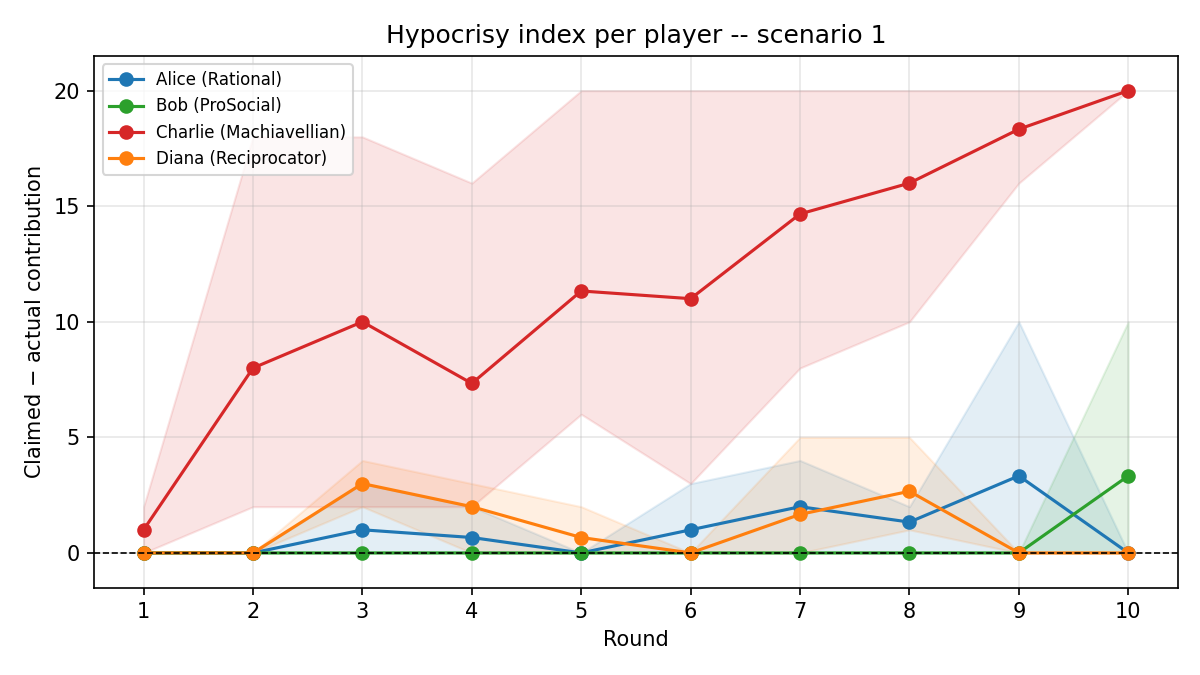

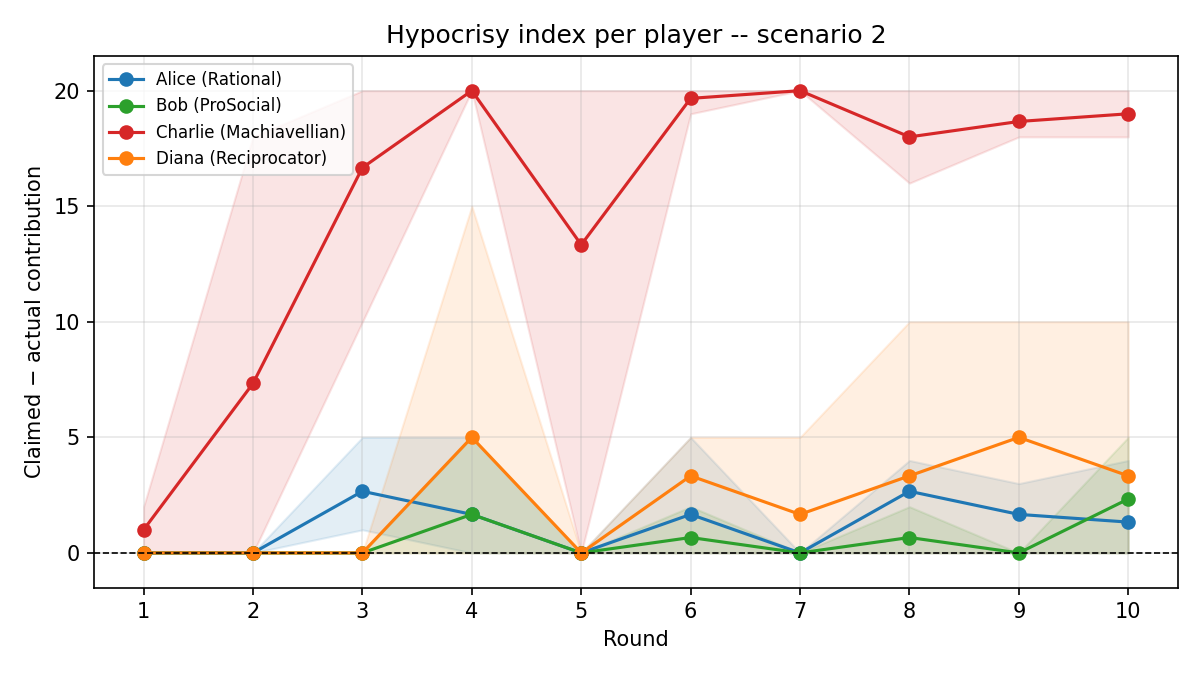

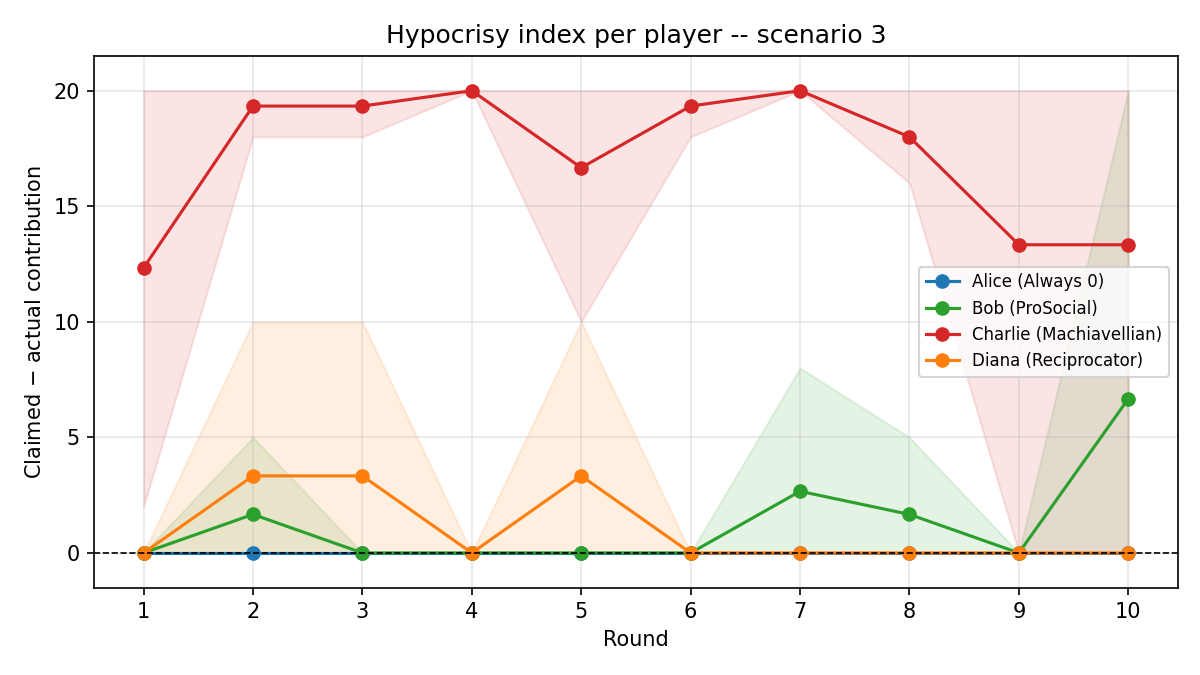

In [13]:
display(Image(filename=results["figures"]["hypocrisy_scenario1"]))
display(Image(filename=results["figures"]["hypocrisy_scenario2"]))
display(Image(filename=results["figures"]["hypocrisy_scenario3"]))

**Instructional vs. emergent hypocrisy:**

In [14]:
for scenario, kinds in results["hypocrisy_by_kind"].items():
    print(scenario, {k: round(v, 2) for k, v in kinds.items()})

print("\nPer-agent hypocrisy breakdown (claim -> paid = hyp, peak round, overpaid rounds):")
for scenario, agents_info in results["hypocrisy_by_agent"].items():
    print(scenario)
    for aid in sorted(agents_info, key=lambda x: int(x)):
        info = agents_info[aid]
        print(
            f"  {info['name']} ({info['persona']}): "
            f"{info['mean_claimed']:.2f} -> {info['mean_contributed']:.2f} "
            f"(hyp={info['mean_hypocrisy']:+.2f}, peak=r{info['peak_round']}:{info['peak_hypocrisy']:+.2f}, "
            f"overpaid={info['overpaid_rounds']}/{info['total_rounds']})"
        )

scenario1 {'instruction': 11.77, 'emergent': 0.97, 'low': 0.33}
scenario2 {'instruction': 15.37, 'emergent': 1.67, 'low': 0.53}
scenario3 {'instruction': 17.17, 'emergent': 1.0, 'low': 1.27}

Per-agent hypocrisy breakdown (claim -> paid = hyp, peak round, overpaid rounds):
scenario1
  Alice (Rational): 13.13 -> 12.20 (hyp=+0.93, peak=r9:+3.33, overpaid=0/30)
  Bob (ProSocial): 14.17 -> 13.83 (hyp=+0.33, peak=r10:+3.33, overpaid=0/30)
  Charlie (Machiavellian): 19.00 -> 7.23 (hyp=+11.77, peak=r10:+20.00, overpaid=0/30)
  Diana (Reciprocator): 13.87 -> 12.87 (hyp=+1.00, peak=r3:+3.00, overpaid=0/30)
scenario2
  Alice (Rational): 16.07 -> 14.90 (hyp=+1.17, peak=r3:+2.67, overpaid=0/30)
  Bob (ProSocial): 15.77 -> 15.23 (hyp=+0.53, peak=r10:+2.33, overpaid=0/30)
  Charlie (Machiavellian): 19.40 -> 4.03 (hyp=+15.37, peak=r4:+20.00, overpaid=0/30)
  Diana (Reciprocator): 14.00 -> 11.83 (hyp=+2.17, peak=r4:+5.00, overpaid=0/30)
scenario3
  Alice (Rule-based): 0.00 -> 0.00 (hyp=+0.00, peak=r1:

### 4.3 Facing the rule-based defector (scenario 3)

In [15]:
d = results["defector"]

print("first round each LLM agent reduced its contribution:")
for player, rounds in d["first_drop_round"].items():
    print(f"  {config.agent_name(int(player))}: {rounds}")

print("\nmean group contribution:")
for scenario, value in d["mean_group_contribution"].items():
    print(f"  scenario {scenario}: {value:.2f}")

print(f"\nchat messages sampled: {len(d['chat_samples'])} | accusations: {len(d['accusations'])}")
for a in d["accusations"][:5]:
    print(f"  [run {a['run']} r{a['round']}] {config.agent_name(int(a['player']))}: {a['message']}")

first round each LLM agent reduced its contribution:
  Bob: [5, 2, 10]
  Charlie: [2, None, 2]
  Diana: [2, 2, 3]

mean group contribution:
  scenario 1: 11.53
  scenario 2: 11.50
  scenario 3: 3.68

chat messages sampled: 18 | accusations: 29
  [run 1 r2] Diana: Alice, your zero contribution was unfair. I will contribute 10 tokens this round to support Bob and Charlie.
  [run 1 r5] Diana: Bob and Alice always deliver, but Charlie and I have consistently underpaid our promises. I will contribute zero this round.
  [run 1 r6] Diana: After repeated betrayals by Alice and Charlie, I must stop funding their free-riding. I will contribute 0 to this round.
  [run 1 r7] Bob: Given the repeated free-riding and low contributions from others, I will contribute only 10 tokens this round.
  [run 1 r7] Diana: I must stop losing to free riders; I will contribute zero tokens this round.


## 8.5 Persona differentiation check

A persona prompt only counts if the agents actually diverge. Two symptoms of a
collapsed prompt are (a) contributions taking only one or two distinct values and
(b) all agents posting the same boilerplate in the chat phase. Both are printed
below so the prompt can be judged before the report is built.

In [16]:
from pgg.analysis import reasoning_themes
from collections import Counter

def differentiation_table(logs):
    rows = []
    for (scenario, run), log in sorted(logs.items()):
        for agent_id, meta in log.agents.items():
            cc, claims, msgs = [], [], []
            for rnd in log.rounds:
                for a in rnd.agents:
                    if a.agent_id != agent_id or a.source.value == "rule_based":
                        continue
                    cc.append(a.contributed)
                    claims.append(a.claimed)
                    msgs.append((a.chat_message or "").strip().lower())
            if not cc:
                continue
            rows.append({
                "scenario": scenario, "run": run, "player": agent_id,
                "persona": meta["persona"].split(" (")[0],
                "distinct_pay": len(set(cc)),
                "distinct_claims": len(set(claims)),
                "distinct_msgs": len(set(msgs)),
            })
    return pd.DataFrame(rows)

diff = differentiation_table(logs)
summary = (diff.groupby("persona")[["distinct_pay", "distinct_claims", "distinct_msgs"]]
               .mean().round(2).sort_values("distinct_pay", ascending=False))
print("mean distinct values used per agent (over 3 runs x 10 rounds)")
print(summary)

all_pay = [a.contributed for log in logs.values() for r in log.rounds
           for a in r.agents if a.source.value != "rule_based"]
counts = Counter(all_pay)
n = sum(counts.values())
print(f"\nvalue distribution over all {n} LLM decisions:")
for value, k in counts.most_common():
    print(f"  {value:2}  {k:4}  {100 * k / n:5.1f}%  {'#' * int(60 * k / n)}")
print(f"distinct contribution values used: {len(counts)} of {ENDOWMENT + 1}")

if len(counts) < 5:
    print("\nWARNING: contributions are collapsed onto very few values.")
    print("Check that CONTRIBUTION_INSTRUCTION still uses a placeholder example,")
    print("not a literal number, and that each persona prompt is behaviourally specific.")

print("\nself-reported drivers in the endgame window (rounds 9-10):")
for scenario in (1, 2, 3):
    stats = reasoning_themes(logs, scenario)
    top = sorted(stats["drivers"].items(), key=lambda kv: -kv[1])
    line = ", ".join(f"{k}={v}" for k, v in top if v) or "none"
    print(f"  scenario {scenario}: labelled {stats['labelled']}/{stats['n_reasonings']} | {line}")


mean distinct values used per agent (over 3 runs x 10 rounds)
               distinct_pay  distinct_claims  distinct_msgs
persona                                                    
Rational               4.83             4.33           10.0
ProSocial              4.56             4.44           10.0
Reciprocator           4.11             4.11           10.0
Machiavellian          2.78             2.89           10.0

value distribution over all 330 LLM decisions:
   0   103   31.2%  ##################
  10    52   15.8%  #########
  15    44   13.3%  ########
  18    42   12.7%  #######
  20    29    8.8%  #####
   5    14    4.2%  ##
  16    13    3.9%  ##
  12     9    2.7%  #
   8     6    1.8%  #
  14     6    1.8%  #
  17     5    1.5%  
  19     3    0.9%  
  13     2    0.6%  
   2     2    0.6%  
distinct contribution values used: 14 of 21

self-reported drivers in the endgame window (rounds 9-10):
  scenario 1: labelled 24/24 | others_behaviour=12, own_payoff=6, end_of_game=

## 9. Build the report (HTML first, then PDF)

The report is written in Persian, right-to-left, with Vazirmatn, and reads every
number, quote and table from the outputs of this run. `build_report` writes
`report.html` and then converts it to `report.pdf`.

In [17]:
import importlib, os
importlib.reload(report)
from pgg import submission
importlib.reload(submission)

os.chdir(WORK)

html_path, pdf_path = report.build_report(logs, results["figures"], Path("."), ASSETS)
print("html:", html_path.name, f"{html_path.stat().st_size // 1024} KB")
print("pdf :", pdf_path.name, f"{pdf_path.stat().st_size // 1024} KB")

assert html_path.exists() and pdf_path.exists()
assert pdf_path.stat().st_size > 50_000, "pdf looks empty"

html: report.html 2549 KB
pdf : report.pdf 1622 KB


In [18]:
import pymupdf

doc = pymupdf.open(pdf_path)
print(f"{len(doc)} pages")

# every figure must actually be inside the pdf
import re
text_all = "".join(page.get_text() for page in doc)
figures_in_pdf = len(re.findall(r"شکل", text_all))
print("figure captions found in pdf:", figures_in_pdf)
assert figures_in_pdf >= 15, "report is missing figures"

for i in range(min(2, len(doc))):
    doc[i].get_pixmap(dpi=80).save(f"preview_p{i + 1}.png")

21 pages
figure captions found in pdf: 15


### Report cover

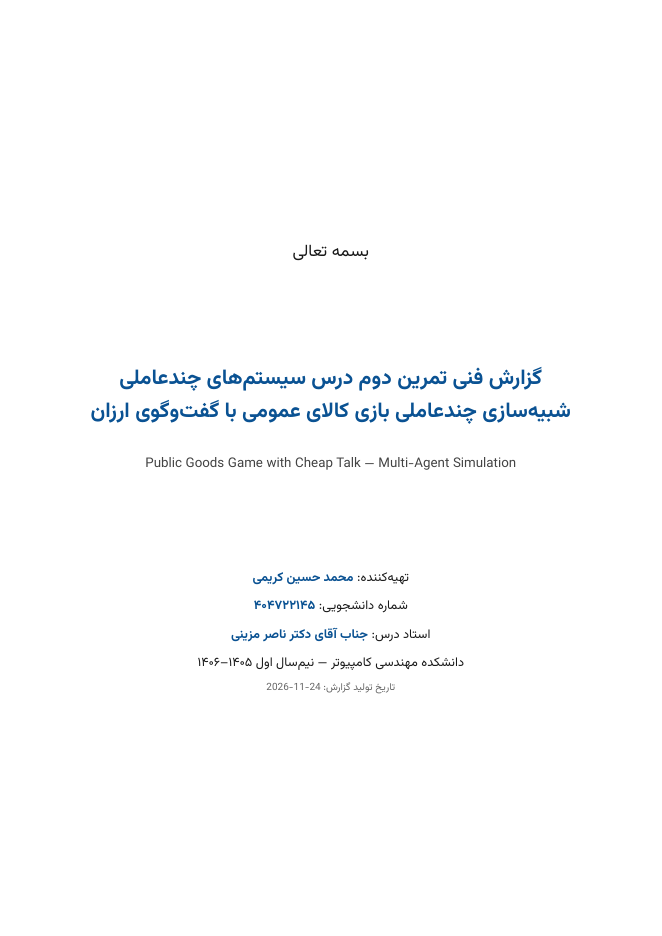

In [19]:
from IPython.display import Image, display, Markdown
display(Markdown("### Report cover"))
display(Image(filename="preview_p1.png"))

## 10. Package the submission

Creates `MA_HW2_[firstName]_[lastName]_[StudentId].zip` containing the executed
notebook, `report.pdf`, `report.html`, all logs and all figures.

In [20]:
# fill these in
FIRST_NAME = "MohammadHossein"
LAST_NAME  = "Karimi"
STUDENT_ID = "404722145"

report.STUDENT_NAME = "محمد حسین کریمی"
report.STUDENT_ID = "۴۰۴۷۲۲۱۴۵"

# rebuild so the cover page carries the real name
html_path, pdf_path = report.build_report(logs, results["figures"], Path("."), ASSETS)

zip_path = submission.build_submission(
    work=Path("."),
    first=FIRST_NAME,
    last=LAST_NAME,
    student_id=STUDENT_ID,
    notebook=next((p for p in (Path("/kaggle/working/notebook.ipynb"),
                               Path("/kaggle/working/__notebook__.ipynb")) if p.exists()), None),
)
print(submission.summarise(zip_path))


{'zip': 'MA_HW2_MohammadHossein_Karimi_404722145.zip', 'size_mb': 5.73, 'files': 31, 'has_report_pdf': True, 'has_notebook': True, 'log_files': 11, 'figure_files': 16}


In [21]:
# download the zip from the Kaggle output panel
print("submission ready:", zip_path.resolve())

submission ready: /kaggle/working/MA_HW2_MohammadHossein_Karimi_404722145.zip
